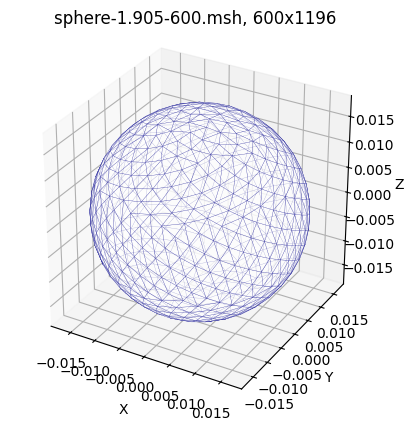

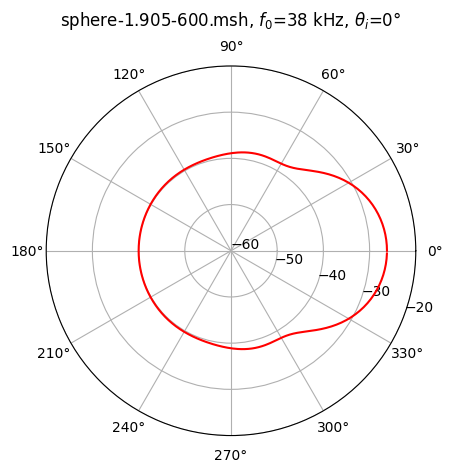

#deg	ls
0	0.048763
1	0.0487363
2	0.0486563
3	0.0485233
4	0.0483375
5	0.0480997
6	0.0478104
7	0.0474706
8	0.0470812
9	0.0466435
10	0.0461586
11	0.0456281
12	0.0450535
13	0.0444365
14	0.0437789
15	0.0430827
16	0.0423498
17	0.0415825
18	0.0407829
19	0.0399535
20	0.0390966
21	0.0382147
22	0.0373105
23	0.0363865
24	0.0354454
25	0.03449
26	0.0335231
27	0.0325475
28	0.031566
29	0.0305816
30	0.0295972
31	0.0286157
32	0.02764
33	0.0266731
34	0.025718
35	0.0247775
36	0.0238547
37	0.0229524
38	0.0220734
39	0.0212207
40	0.0203969
41	0.0196047
42	0.0188468
43	0.0181255
44	0.017443
45	0.0168014
46	0.0162024
47	0.0156474
48	0.0151375
49	0.0146732
50	0.0142546
51	0.0138814
52	0.0135525
53	0.0132665
54	0.0130215
55	0.0128149
56	0.0126439
57	0.0125054
58	0.012396
59	0.0123123
60	0.0122507
61	0.0122078
62	0.0121802
63	0.012165
64	0.0121591
65	0.01216
66	0.0121652
67	0.0121728
68	0.0121809
69	0.0121879
70	0.0121927
71	0.0121942
72	0.0121916
73	0.0121841
74	0.0121716
75	0.0121535
76	0.0121299
77	0.0121008


In [2]:
# MM 19.5.2025: scattering from soft body
# !pip install --force-reinstall "numpy<=2.2" scipy bempp-cl matplotlib

datapath="../msh/"

import bempp_cl as bempp
from bempp_cl.api.operators.boundary import helmholtz as boundary
from bempp_cl.api.operators.potential import helmholtz as potential
from bempp_cl.api.linalg import gmres
#from scipy.linalg import gmres
from numpy import pi,sin,cos,exp,log10,abs,array,linspace

# input parameters
fname = 'sphere-1.905-600.msh'
th = 0
f0 = 38e3 
c0 = 1480

k0 = 2*pi*f0/c0                             # wave numbers
d = array([cos(pi/180*th),sin(pi/180*th),0])# plane wave direction
#d = array([0, -1.0, 0])                     # plane wave direction

# target mesh and its space
#grid = bempp.api.shapes.sphere(r=0.01905, h=c0/f0/5) # generated mesh
grid = bempp.api.import_grid(datapath+fname)
Sp = bempp.api.function_space(grid, "P", 1)

# incident pressure 
@bempp.api.complex_callable
def pinc(x, n, idx, res): res[0] = exp(1j*k0*d.dot(x))
f = bempp.api.GridFunction(Sp, fun=pinc)

# surface solution
S = boundary.single_layer(Sp, Sp, Sp, k0)
u,_ = gmres(S, -f)

# far field solution
#r1 = array([[sin(2*pi*i/360),-cos(2*pi*i/360),0] for i in range(360)]).T
r1 = array([[cos(i*pi/180),sin(i*pi/180),0] for i in range(360)]).T
SL = potential.single_layer(Sp, r1, k0)
psc = - SL.evaluate(u)

# plot mesh
v = grid.vertices.T  # Transpose to shape (N, 3)
e = grid.elements.T  # Transpose to shape (M, 3)
n,m = len(v),len(e)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
tri = [[array(v[i]) for i in t] for t in e]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
mesh_collection = Poly3DCollection(tri, alpha=0.6)
mesh_collection.set_facecolor('white')
mesh_collection.set_edgecolor('darkblue')
mesh_collection.set_linewidth(0.2)
ax.add_collection3d(mesh_collection)
v_arr = array(v)
ax.set_xlim(v_arr[:, 0].min(), v_arr[:, 0].max())
ax.set_ylim(v_arr[:, 1].min(), v_arr[:, 1].max())
ax.set_zlim(v_arr[:, 2].min(), v_arr[:, 2].max())
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title(r"%s, %dx%d"%(fname,n,m))
plt.savefig("soft_bempp_1.svg", format="svg", bbox_inches="tight")
plt.show()

# plot solution
import matplotlib.pyplot as plt
angles = linspace(0, 2 * pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc[0]])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, color='red')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title(r"%s, $f_0$=%g kHz, $\theta_i$=%g$\degree$"%(fname,f0/1e3,th), va='bottom')
plt.savefig("soft_bempp_2.svg", format="svg", bbox_inches="tight")
plt.show()

# print
print("#deg\tls")
print("\n".join(["%d\t%g"%(i,abs(psc[0][i])) for i in range(len(psc[0]))]))

